# Análisis ConnectaTel

El objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajaré con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Se requiere **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis permite **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.



--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario familiarizarnos con la estructura de los tres datasets.  
En esta etapa, validaremos que los archivos se carguen correctamente, conoceremos sus columnas y tipos de datos, y detectaremos posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importar las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Cargar los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guardar los DataFrames en las variables: `plans`, `users`, `usage`.  
- Mostrar las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Pasos:**  
- Revisar el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usar `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


**Conclusiones** 

En el DataFrame plans podemos observar que tiene 8 columnas y tan solo 2 registros, 7 columnas son númericas menos la primera "plan_name" que es tipo objet

En el DataFrame users observamos que las columnas "reg_date" y "churn_date" son tipo object pero deberían ser tipo datetime, cuenta también con 8 columnas y 4000 registros.

En el DataFrame usage encontramos solo 6 columnas pero tiene 40000 registros, también tiene una columna (date) que debería ser datetime pero es objet.

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Pasos:**  
- Contar valores nulos por columna para cada dataset.
- Calcular la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())# cantidad de nulos para usage
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64




**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

  En el DataFrame de users de las 8 columnas solo 2 presentan valores ausentes (city y churn_date), city muestra 469 valores nulos que representan el 11.73% del total de registros, en la columna de churn_date hay 3534 registros nulos (88.35% del total de registros).

  En el DataFrame usage se visualizan 50 valores nulos para "date" lo que representa un 0.125% de los datos, 22076 valores nulos en duration (55.19%) y 17896 valores nulos en length, lo que representa el 44.74% del total de los datos.

  
- Desiciones: ¿imputar, eliminar, ignorar?

   users.city: Recomiendo convertir los valores "?" a NA, ya que no conocemos su vvalor real, así evitamos inventar ciudades y distorsionar el análisis --> Imputar a NA

  
    users.churn_date: Muestra que son usuarios que no se han dado de baja, por lo que no representa un error, sino una realidad normal de negocio. --> Ignorar

  
    usage.date: Se recomienda imputar a NA estos registros ya que no tendrán un impacto significativo para el análisis y así no inventamos valores ni perdemos infromación relevante. --> Imputar

  
    usage.duration y usage.length: Es el comportamiento normal de la metrica ya que en este caso indica el detalle de las 2 opciones de servicio, si no aplica uno tiene que ser el otro, la diferencia con el total de los datos es de 0.07%. --> Ignorar

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Pasos:**
- Explorar las columnas numéricas con **un resumen estadístico** y describir brevemente los hallazgos.
- Explorar las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users["age"].describe()

count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

- La columna `user_id` no la tendré en cuenta ya que considero que no aportará ningúna conclusión relevante al análisis de datos mas allá de una númericación que empieza desde 10000.
- La columna `age` por el contrario aporta información relevante ya que visualizamos sentinels de -999 en el valor min del resumen estadístico, lo que aumenta la desviación estandar, pero por lo demás se ve muy centrada y sin sesgos aparentes.

In [13]:
# explorar columnas numéricas de usage
columnas_usage = ['duration', 'length']
display(usage[columnas_usage].describe())

,duration,length
count,17924.000000,22104.000000
mean,5.202237,52.127398
std,6.842701,56.611183
min,0.000000,0.000000
25%,1.437500,37.000000
50%,3.500000,50.000000
75%,6.990000,64.000000
max,120.000000,1490.000000


- En la descripción estadisitica de duration y length podemos observar valores coherentes ya que no hay valores negativos, sin embargo si observamos los valores maximos frente al percentil 75% determinamos que hay presencia de outliers en ambas columnas.

- Las columnas `id` y `user_id`no la tendré en cuenta ya que considero que no aportará ningúna conclusión relevante al análisis de datos mas allá de una númericación secuencial de las 40mil filas.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
display(users[columnas_user].describe())
display(users[columnas_user].value_counts())
users['city'].value_counts(dropna=False)

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

- La columna `city` muestra 3531 registros con valor, aunque se aprecian valores "?" tanto para plan basico como premium, muestra también 7 valores unicos y Bogotá es el top con 808 registros sumando basico y premium.
- La columna `plan` muestra excelente estandarización, solo refleja 2 valores únicos (Basico y Premium) siendo basico el top con 2595 registros.

In [15]:
# explorar columna categórica de usage
display(usage['type'].describe())
usage["type"].value_counts()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` muestra dos únicos valores que cubren los 40mil registros, siendo text el top con 22092 registros, el restante corresponden al valor "call", no hay presencia de nulos.


---

**Valores inválidos o sentinels**  
- ¿En qué columnas se hallaron valores inválidos o sentinels?

    users.age: Hay presencia de sentinels (-999), se recomienda normalizar aplicando la mediana!.
  
    user.city: Hay presencia de valores nulos, se debe profundizar para encontrar la razón, también hay valores inválidos ("?"), al representar menos de un 5% del dataframe se recomienda convertirlos a nulos en el análisis actual pero tomar acción para determinar una mejor forma en la obtención de datos a futuro.
 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Pasos:**  
- Convertir las columnas de fecha a tipo fecha y asegurar que el código sea a prueba de errores.  
- Revisar cuántas veces aparece cada año.
- Identificar fechas imposibles (ej. años futuros o negativos).

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors = "coerce")
users["year"] = users["reg_date"].dt.year# completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors = "coerce")
usage["year"] = usage["date"].dt.year# completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users["year"].value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: year, dtype: int64

En `reg_date`, decidí crear una nueva columna de nombre "year" para extraer solo la información del año, después de verificar los datos de la columna encontre 40 registros inválidos ya que muestran como año "2026", una fecha imposible si tenemos en cuenta que el análisis se realiza con datos unicamente **hasta** 2024.

In [19]:
# Revisar los años presentes en `date` de usage
usage["year"].value_counts(dropna=False)

2024.0    39950
NaN          50
Name: year, dtype: int64

En `date`, nuevamente decidí crear una nueva columna en este dataframe de nombre "year", se observa que todos los registros pertenecen al 2024 y también se reflejan los 50 valores nulos que habiamos identificado antes.  
Basaremos el análisis en estas fechas.

**Fechas fuera de rango**  

  Para los 40 registros con valor users.year = 2026 **la sugerencia es convertirlos en valores nulos** para este análisis y no entrar en investigaciones, representas solo el 1% de los datos y no tendrá un impacto relevante en las conclusiones.

  En el caso de los 50 valores nulos en usage.year mi recomendación es normalizarlos con el unico valor presente en esta columna (2024) ya que seguramente fue un olvido humnano.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Pasos:**  
- En `age`, reemplazar el sentinel **-999** con la mediana.
- En `city`, reemplazar el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marcar como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users["age"].replace(-999, age_mediana)

# Verificar cambios
#users['age'].describe()
users["age"].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", pd.NA)
users["city"].value_counts()
# Verificar cambios

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [ ]:
# Marcar fechas futuras como NA para reg_date)
users.loc[users["reg_date"].dt.year>2024, "reg_date"] = pd.NaT
# Verificar cambios
users["reg_date"].value_counts(dropna=False)

NaT                              40
2023-03-31 06:21:20.120030008     1
2024-06-20 09:50:54.463615904     1
2022-05-22 00:23:45.956489122     1
2022-04-23 06:22:24.936234060     1
                                 ..
2022-07-29 04:44:06.661665416     1
2022-02-22 00:36:43.750937734     1
2022-10-31 09:22:49.242310580     1
2022-09-24 16:46:48.702175544     1
2022-03-28 12:38:20.975243811     1
Name: reg_date, Length: 3961, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Pasos:**
- Verificar si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  De ser MAR, se dejan como nulos.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duracion_faltante"] = usage["duration"].isna()
usage.groupby("type")["duracion_faltante"].mean()


type
call    0.000000
text    0.999276
Name: duracion_faltante, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage["extension_faltante"] = usage["length"].isna()
usage.groupby("type")["extension_faltante"].mean()


type
call    0.99933
text    0.00000
Name: extension_faltante, dtype: float64

Diagnostico de nulos en `duration` y `length`

Los datos faltantes observados en el DataFrame usage en las columnas "duration" y "length" indican un tipico comportamiento **MAR** ya que según el tipo de servicio le corresponde un valor en "duration" **O** en "length", los datos muestran claramente que cuando es tipo llamada la columna "length" es nula en mas de un 99.9% mientras que opuestamente el tipo text es 99.9% nulo en la columna "duration".
Por esta razón no se dará tratamiento a los datos nulos y se conservarán tal cual por tratarse del comportamiento natural del negocio. Este patrón se conoce como estructural/esperado, no es un dato perdido al azar, también se observa que no cubre el 100% de los registros lo que puede indicar un posible error en 28 filas del total de registros.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Pasos:**: 
1. Construir una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Combinar esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes = ("is_text", "sum"),
    cant_llamadas = ("is_call", "sum"),
    cant_minutos_llamada = ("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on = "user_id", how = "left")
user_profile.fillna({
    'cant_mensajes': 0,
    'cant_llamadas': 0,
    'cant_minutos_llamada': 0
}, inplace=True)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Pasos:**  
1. Para las columnas **numéricas** relevantes, obtener un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisar la distribución en **porcentajes** de cada categoría.

In [27]:
# Filtrar para obtener solo usuarios durante el 2024
user_profile.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4000 entries, 0 to 3999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               4000 non-null   int64         
 1   first_name            4000 non-null   object        
 2   last_name             4000 non-null   object        
 3   age                   4000 non-null   float64       
 4   city                  3435 non-null   object        
 5   reg_date              3960 non-null   datetime64[ns]
 6   plan                  4000 non-null   object        
 7   churn_date            466 non-null    object        
 8   year                  4000 non-null   int64         
 9   cant_mensajes         4000 non-null   float64       
 10  cant_llamadas         4000 non-null   float64       
 11  cant_minutos_llamada  4000 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(5)
memory usage: 406.2+ K

In [28]:
# Resumen estadístico de las columnas numéricas[columnas_numericas].describe()
columnas_numericas = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

user_profile[columnas_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.122250,5.523000,4.477000,23.311225
std,17.690408,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize = True) * 100


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Pasos:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribir un **insight** respecto al plan y la variable.  

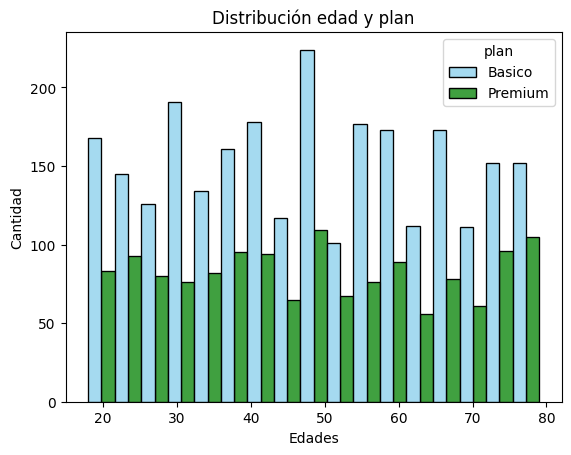

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data = user_profile, x = "age", hue = "plan", palette = ["skyblue", "green"], multiple='dodge')
plt.title("Distribución edad y plan")
plt.xlabel("Edades")
plt.ylabel("Cantidad")
plt.show()

💡Insights: 
- El histograma muestra como la distribución entre plan premium y plan básico es uniforme a lo largo del rango de edad, no se establece un patrón claro donde se pueda concluir que determinada edad usa significativamente mas un plan que el otro arrojando una distribución uniforme, por otro lado se observa graficamente como en todas las edades el plan básico supera el plan premium mostrando un comportamiento sano para la empresa teniendo en cuenta que el costo del plan premium es practicamente el doble del plan premium (25 y 12 usd respectivamente) y si traemos el porcentaje de suscripción se establece una clara relación (35.12% para premium y 64.87% para básico).

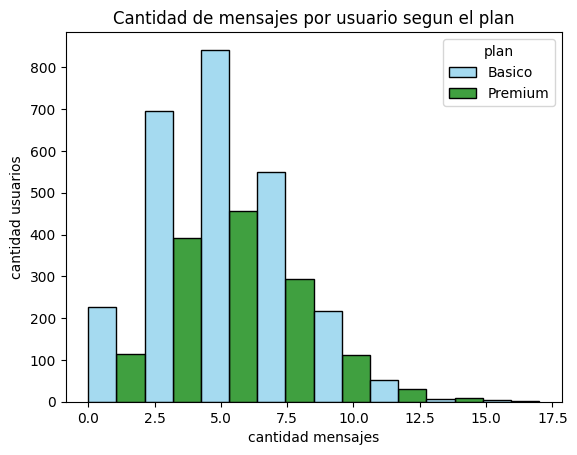

In [31]:
# Histograma para visualizar la cant_Mensajes
sns.histplot(data = user_profile, x = "cant_mensajes", bins = 8, hue = "plan", palette = ["skyblue", "green"], multiple='dodge')
plt.title("Cantidad de mensajes por usuario segun el plan")
plt.xlabel("cantidad mensajes")
plt.ylabel("cantidad usuarios")
plt.show()

💡Insights: 
- El histograma muestra un ligero sesgo a la derecha indicando que la mayoría de datos se concentran en cantidades mas bajas, puntualmente se observa una gran concentración entre los 2 y los 8 mensajes. Unos pocos usuarios que envian mas de 12 mensajes halan el promedio. Ademas se ve que aunque el uso del plan básico supera al de premium, ambas distribuciones tiene un comportamiento similar indicando que los usuarios que mantienen el plan premium no es debido a la capacidad de mensajes dentro del plan.

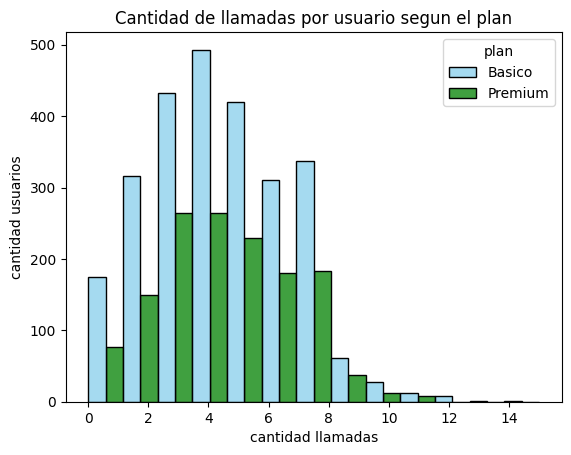

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data = user_profile, x = "cant_llamadas", bins = 13, hue = "plan", palette = ["skyblue", "green"], multiple='dodge')
plt.title("Cantidad de llamadas por usuario segun el plan")
plt.xlabel("cantidad llamadas")
plt.ylabel("cantidad usuarios")
plt.show()

💡Insights: 
- Podemos observar en el histograma asimetría positiva gracias a la cola que hay a la derecha, nuevamente se observa concentración de datos en valores similares al de mensajes, en esta ocasión entre 1 y 8 llamadas. Se repite la mayor concentración en usuarios de plan básico sobre premium, siendo 4 llamadas el valor de moda con casi 500 registros, mientras que en el plan premium la moda esta entre las 3 y las 5 llamadas con unos 280 usuarios. Apreciamos nuevamente que apesar de la diferencia entre la cantidad de usuarios de ambos planes el comportamiento si es similar y pocos usuarios realizan mas de 9 llamadas.

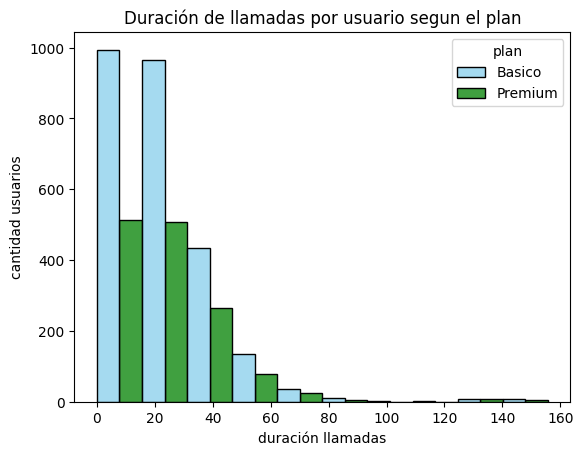

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data = user_profile, x = "cant_minutos_llamada", bins = 10, hue = "plan", palette = ["skyblue", "green"], multiple='dodge')
plt.title("Duración de llamadas por usuario segun el plan")
plt.xlabel("duración llamadas")
plt.ylabel("cantidad usuarios")
plt.show()

💡Insights: 
- En el historama de la duración de las llamadas si se observa un fuerte sesgo a la derecha, por este motivo no se recomienda usar el promedio ya que los outliers distorsionan mucho la realidad del comportamiento en la duración de las llamadas, es mas recomendable usar la mediana!.
- Este histograma es superimportante porque refleja el comportamiento común de ambos planes, los usuarios de plan básico y premium tienen un comportamiento similar teniendo la cantidad de minutos consumidos en rangos entre 1 y 50 a 60 minutos, son muy pocos los usuarios que llegan al consumo de los 100 minutos lo que se puede entender en el plan básico, sin embargo en el plan premium pagan por 600 minutos y ningun usuario supera 156 minutos en el total de sus llamadas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Pasos:**  
- Usar **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crear un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráficos, responder si **existen o no outliers** en las variables.  
- Si hay outliers, crear otro bucle para calcular los límites de esas columnas usando el **método IQR** y decidir qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

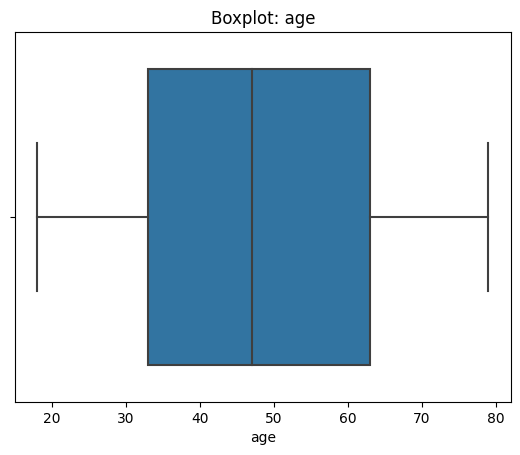

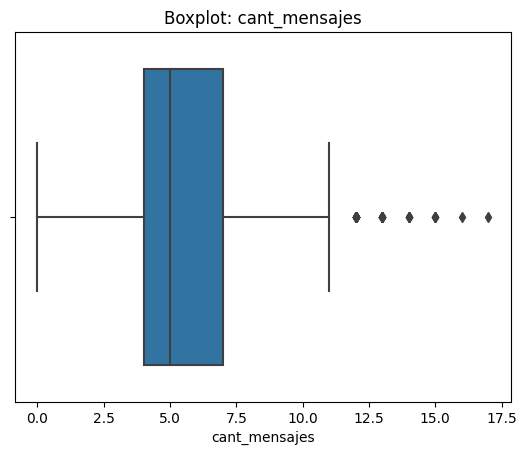

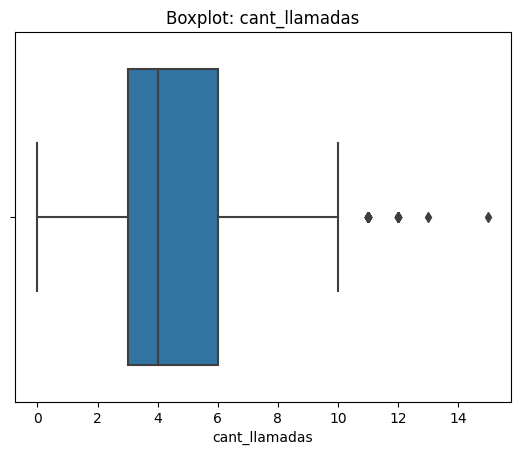

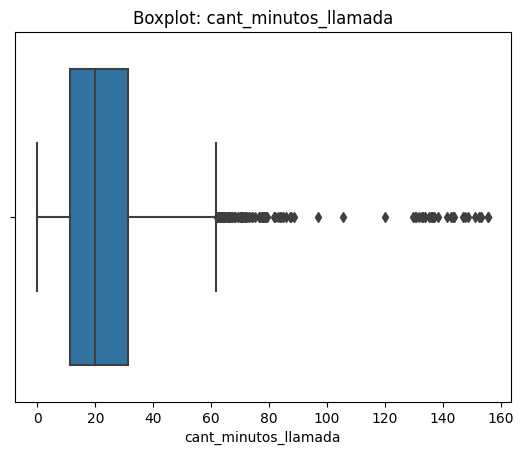

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data = user_profile, x = col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: En la columna de edad no se presenta ningún outlier, de hecho tiene una distribución simetrica según el boxplot.
- cant_mensajes: En la columna cantidad de mensajes si se evidencian outliers entre los valores 11 y 16 mensajes.
- cant_llamadas: En la columna cantidad de llamadas también se observan outliers a la derecha en un intervalo aproximado entre las 11 y las 13 llamadas
- cant_minutos_llamada: Finalmente en la columna cantidad de minutos por llamada encontramos la mayor dispersión de datos al observar una larga cola a la derecha  con valores muy altos por encima del límite superior.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    IQR = q3 - q1
    limite_superior = q3 + 1.5 * IQR
    print(col)
    print("limite superior: ", limite_superior)

cant_mensajes
limite superior:  11.5
cant_llamadas
limite superior:  10.5
cant_minutos_llamada
limite superior:  61.870000000000005


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
      Yo recomendaría mantener los outliers ya que no representan valores imposibles y marcan mas el tipo de consumo de super cliente, al no estar ampliamente alejados del límite superior yo aplicaría winsorización.
- cant_llamadas: mantener o no outliers, porqué?
      Como en el caso de los mensajes para las llamadas tambien mantendría los outliers por la misma razçon y aplicando el mismo método de winsorización.
- cant_minutos_llamada: mantener o no outliers, porqué?
      En el caso de la duración de las llamadas el comportamiento cambia ya que hay varios valores muy por encima del límite superior, para este caso siento que winsorizar no es lo mas conveniente ya que se pierde información real de super clientes que si generan un consumo atípico. Aquí simplemente usaría el mètodo keep.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Pasos:**  
- Crear una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usar comparaciones lógicas para evaluar las condiciones de llamadas y mensajes y asignar:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso


def definir_uso(row):
    if row["cant_mensajes"] < 5 and row["cant_llamadas"]< 5:
        return "Bajo uso"
    elif row["cant_mensajes"] < 10 and row["cant_llamadas"]< 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile["grupo_uso"] = user_profile.apply(definir_uso, axis = 1)
display(user_profile["grupo_uso"].value_counts(dropna = False))
user_profile["grupo_uso"].value_counts(normalize = True)*100

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

Uso medio    73.575
Bajo uso     19.475
Alto uso      6.950
Name: grupo_uso, dtype: float64

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Pasos:**  
- Crear una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usar comparaciones lógicas para evaluar las condiciones y asignar:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
def segmentar_edad(row):
    if row["age"] < 30:
        return "Joven"
    elif row["age"] < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile["grupo_edad"] = user_profile.apply(segmentar_edad, axis = 1)
display(user_profile["grupo_edad"].value_counts(dropna = False))
user_profile["grupo_edad"].value_counts(normalize = True)*100

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [41]:
# Cruce en cantidades absolutas
cruzado_counts = pd.crosstab(
    user_profile['grupo_edad'], 
    user_profile['grupo_uso'], 
    margins=True
)
print(cruzado_counts)

# Cruce en porcentajes
cruzado_pct = pd.crosstab(
    user_profile['grupo_edad'], 
    user_profile['grupo_uso'], 
    normalize='all', 
    margins=True
) * 100
print(cruzado_pct.round(2))

grupo_uso     Alto uso  Bajo uso  Uso medio   All
grupo_edad                                       
Adulto             153       365       1500  2018
Adulto Mayor        74       257        891  1222
Joven               51       157        552   760
All                278       779       2943  4000
grupo_uso     Alto uso  Bajo uso  Uso medio     All
grupo_edad                                         
Adulto            3.82      9.12      37.50   50.45
Adulto Mayor      1.85      6.42      22.28   30.55
Joven             1.27      3.92      13.80   19.00
All               6.95     19.48      73.58  100.00


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Pasos:**  
- Crear dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agregar título y etiquetas a los ejes en cada gráfico.

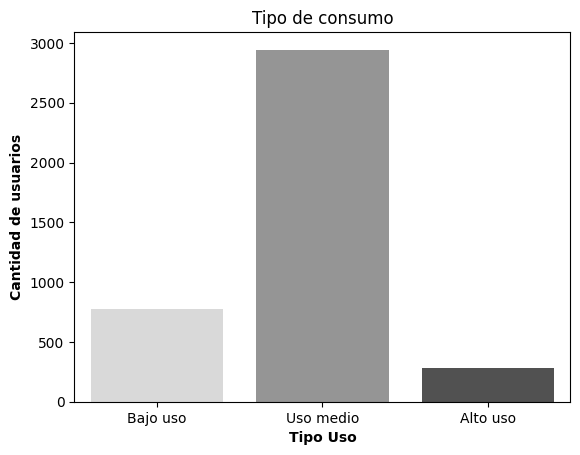

In [42]:
# Visualización de los segmentos por uso
sns.countplot(data = user_profile, x = "grupo_uso", palette = "Greys", order=['Bajo uso','Uso medio','Alto uso'])
plt.title("Tipo de consumo")
plt.xlabel("Tipo Uso", fontweight='bold')
plt.ylabel("Cantidad de usuarios", fontweight='bold')
plt.show()

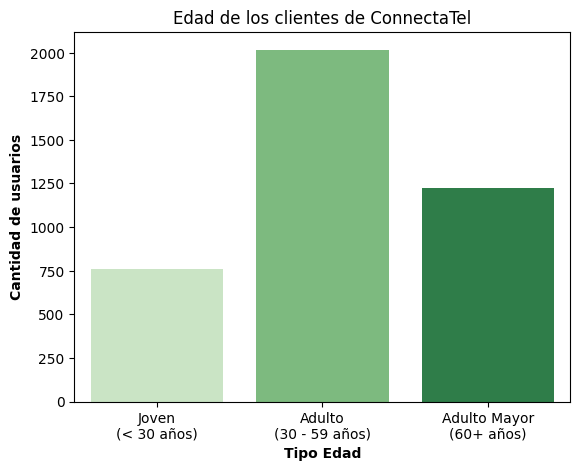

In [43]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, x = "grupo_edad", palette = "Greens", order=['Joven','Adulto','Adulto Mayor'])
plt.title("Edad de los clientes de ConnectaTel")
plt.xticks(
    ticks=[0, 1, 2], 
    labels=["Joven\n(< 30 años)", "Adulto\n(30 - 59 años)", "Adulto Mayor\n(60+ años)"],
)
plt.xlabel("Tipo Edad", fontweight='bold')
plt.ylabel("Cantidad de usuarios", fontweight='bold')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones tienen lugar para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Luego de realizar una exploración de los datos encontré varios problemas de calidad, los detallo a continuación:

        - Tipos de datos: De los 3 DataFrame 2 presentaban datos de fecha como tipo objet.

           - DataFrame Users: columnas reg_date y churn_date.
           - DataFrame Usage: columna date.

        - Valores nulos: En 2 de los 3 DataFrame se evidenciaron valores nulos en diferentes columnas.

            - DataFrame Users: Columna city con 565 valores nulos que representan el 14.12% de los valores totales, columna churn_date con 3534 valores nulos que representan el 88.35% de los valores totales.
            - DataFrame Usage: Columna date con 50 valores nulos que representan el 0.12% de los valores totales, duration con 22076 valores nulos que representan el 55.19% de los valores totales, length con 17896 valores nulos que representan el 44.74% de los valores totales.


        - Sentinels: Encontré 2 tipos de sentinels que requerían atención para el análisis de datos.

            - DataFrame Users: En la columna age encontré valores imposibles (-999) que distorionaban el análisis, en la columna city habia 96 valores "?".
            


Las acciones tomadas para limpiar y organizar los dataframes y entregar mayor calidad en el análisis de datos:
Se creo una nueva columna en los dataframes users y usage llamada year para extraer el año de las fechas de inscripción y de uso de los servicios.

        - Tipo de datos: Se realizó cambio de tipo de dato para las columnas reg_date y date, pasaron de object a datatime.

        - Valores nulos: Los valores nulos siguen presentes en la columna city, en una ampliación del análisis se podría investigar en que casos se usa el valor "?", o si existe una directriz para dejar el campo vacio.
                        Los valores nulos en la columnas duration y length se mantienen ya que identificamos que son tipo MAR y corresponde al comportamiento real de las métricas

        - Sentinels: Para los valores -999 se reemplazaron por la mediana.
                    En la columna city los valores "?" fueron reemplazados por valores NA
                    En la columna reg_date se reemplazaron los 40 valores de 2026 por valores NA.

🔍 **Segmentos por Edad**
Después de segmentar los usuarios por su edad establecemos lo siguiente:

    - En terminos generales la distribución del plan premium y básico esta distrbuido de forma uniforme entre las diferentes edades, mostrando como la anomalía mas notable la diferencia marcada en el rango de edad de 24-28 años donde si se ve una preferencia por el plan premium.

    - También establecí 3 grupos definidos para categorizar la edad de los usuarios (Joven, Adulto, Adulto Mayor) y se observa que la proporción de adultos es casi la suma de jovenes y adultos mayores.


📊 **Segmentos por Nivel de Uso**
De la misma manera segmentamos el uso de los servicios de ConnectaTel para comprender mejor las preferencias y consumo de los clientes.

    - Para el servicio de mensajes encontré un comportamiento simetrico con una ligera cola hacia la derecha que muestra a algunos usuarios haciendo un uso relativamente inusual y mayor al de la mayoría de usuarios, ya que si bien el promedio usan entre 5 y 5.5 mensajes hay otros usuarios que incluso han llegado a los 16 mensajes.

    - En el servicio de llamadas el comportamiento es muy parecido a los mensajes, aquí el promedio esta en 4.5 mientras que la mediana se observa en 4, nuevamente hay algunos datos atípicos que sesgan a la derecha pero sin que sea una tendencia demasiado marcada, en este caso el valor máximo esta en 13 llamadas.

    - En segmento de duración de llamadas si observamos un sesgo a la derecha importante, donde encontré que el 75% de los valores estan por debajo de 33 minutos, sin embaro el valor máximo se aleja casi 5 veces el valor del q3, marcando 155.69 minutos siendo el maximo acumulado de llamadas, en este segmento se observan muchos mas outliers que en los otros dos segmentos.

    - **En el grupo grupo_uso podemos evidenciar que el mayor porcentaje de usuarios tienen un uso medio con un total de 2943 registros (el 73.57%), mientras que el bajo uso y alto uso sumados representan el procentaje restante (Bajo uso = 19.47% y Alto uso = 6.95%)

    - En el grupo grupo_edad evidenciamos que el grupo adulto representa el mayor porcentaje de los usuarios de ConnectaTel con 2018 usuarios (50.45%), el adulto mayor representa el 30.55% con 1222 usuarios y el menor porcentaje de usuarios son los que se encuentran en el grupo Joven con tan solo el 19% y 760 usuarios.

    - Cruzamos los datos de ambos grupos para entender que tipo de cliente representa el mayor consumo arrojando como resultado a los adultos que realizan un uso medio al representar el 37.50% del total de los usuarios (1500 usuarios), mientras que los Jovenes que realizan un alto uso tan solo representan el 1.27% de los usuarios de ConnectaTel (51 usuarios)**


➡️ Esto sugiere que ...

    - Los sementos de llamadas y mensajes muestran un comportamiento general parecido ya que no destaca mucho el uno del otro, por lo que la atención y el esfuerzo debe permanecer para ambos segmentos.

    - Revisando la edad de los usuarios se puede establecer que ConnectaTel llega a las diferentes edades de la población objetivo, aunque el grupo Joven representa el menor porcentaje de usuarios con 760.
    
    - En el uso de llamadas y mensajes se encuentra una distribución asimetrica positiva donde se pueden evidenciar "clientes ballena" que suelen hacer un consumo un poco mayor al promedio.

    - Por otro lado la duración de llamadas si muestra un comportamiento con numerosos outliers que representan una oportunidad de mejora para COnnectaT
    
💡 **Recomendaciones**

Dados los resultados arrojados en este análisis de datos para la empresa ConnectaTel se hacen las siguientes recomendaciones:

    - Dado que un promedio cercano al 50% de los usuarios estan en edad de entre los 30 y los 59 años se recomienda hacer una campaña de fidelización al representar la base de consumo de los productos de la empresa.
    
    - Se puede proyectar la creación de un nuevo plan económico para buscar robustecer la suscripción de personas mas jovenes.
    
    - Se recomienda evaluar una posible sobre dimensión de los minutos ofrecidos en ambos planes, ya que la mayoría de los usuarios tienen un consumo inferior al Q3, se plantea disminuir los minutos ofertados teniendo en cuenta el consumo general o ajustar los planes por el grupo de uso definido en este análisis.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar el análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender el trabajo.



### Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entrar al repositorio en GitHub (`telecom-analysis`).  
3. Subir el notebook **Add file → Upload files**.  


Agregar un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.

Link a repositorio público del proyecto: https://github.com/xxerjio/telecom-analysis